1. Upload & Extract Dataset

In [11]:
from google.colab import files
uploaded = files.upload()

Saving dataset.zip to dataset.zip


In [ ]:
import zipfile
import os

zip_path = "archive.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("data")

print("Dataset extracted!")

Dataset extracted!


2. Check Dataset

In [ ]:
os.listdir("data")

['test', 'train']

In [ ]:
import os
print(os.listdir("data/train"))

['REAL', 'FAKE']


3. Data Preprocessing

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img_size = (224, 224)
batch_size = 32

# Train data (with validation split)
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = train_datagen.flow_from_directory(
    "data/train",
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    subset='training'
)

val_data = train_datagen.flow_from_directory(
    "data/train",
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    subset='validation'
)

# Test data (NO split)
test_datagen = ImageDataGenerator(rescale=1./255)

test_data = test_datagen.flow_from_directory(
    "data/test",
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    shuffle=False
)

Found 80000 images belonging to 2 classes.
Found 20000 images belonging to 2 classes.
Found 20000 images belonging to 2 classes.


In [ ]:
!pip install tensorflow keras matplotlib

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

4. Build CNN Model

In [ ]:
model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


5. Compile Model

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

6. Train Model

In [ ]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=15
)

Epoch 1/15
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 156s 62ms/step - accuracy: 0.9862 - loss: 0.0380 - val_accuracy: 0.9288 - val_loss: 0.3092
Epoch 2/15
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 159s 63ms/step - accuracy: 0.9892 - loss: 0.0317 - val_accuracy: 0.9241 - val_loss: 0.3449
Epoch 3/15
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 154s 62ms/step - accuracy: 0.9913 - loss: 0.0260 - val_accuracy: 0.9257 - val_loss: 0.3880
Epoch 4/15
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 155s 62ms/step - accuracy: 0.9921 - loss: 0.0225 - val_accuracy: 0.9165 - val_loss: 0.5442
Epoch 5/15
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 155s 62ms/step - accuracy: 0.9932 - loss: 0.0206 - val_accuracy: 0.9194 - val_loss: 0.5124
Epoch 6/15
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 157s 63ms/step - accuracy: 0.9942 - loss: 0.0188 - val_accuracy: 0.9222 - val_loss: 0.4431
Epoch 7/15
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 156s 62ms/step - accuracy: 0.9946 - loss: 0.0174 - val_accuracy: 0.9171 - val_loss: 0.4648
Epoch 8/15
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 155s 62ms/step - accuracy: 

7. Evaluate Model

In [ ]:
test_loss, test_acc = model.evaluate(test_data)
print("Test Accuracy:", test_acc)

625/625 ━━━━━━━━━━━━━━━━━━━━ 25s 40ms/step - accuracy: 0.9292 - loss: 0.2414
Test Accuracy: 0.9291999936103821


8. Plot Accuracy

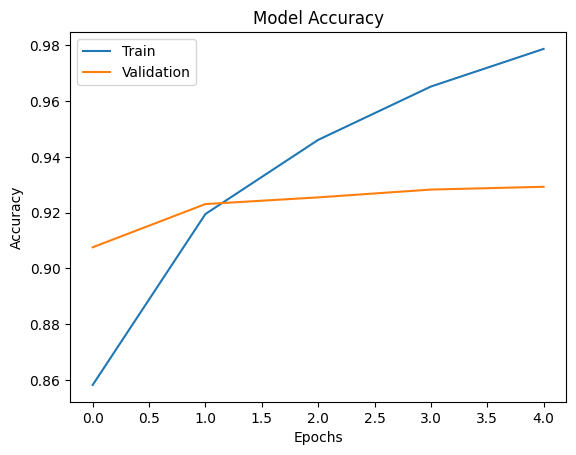

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.legend(['Train', 'Validation'])
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.show()

9. Class Mapping

In [ ]:
print(train_data.class_indices)

{'FAKE': 0, 'REAL': 1}


In [ ]:
prediction = model.predict(img_array)
print("Prediction value:", prediction)

if prediction[0][0] > 0.5:
    print("Real Image")
else:
    print("Fake Image")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Prediction value: [[0.00337731]]
Fake Image


In [ ]:
print(prediction)

[[0.99874145]]


10. Upload & Predict Image

In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np
from google.colab import files # Import files module

# Original line: img_path = "test.jpg"  # upload a test image

# Upload the test image file
print("Please upload your test image (e.g., test.jpg):")
uploaded = files.upload()

if uploaded:
    # Get the name of the first uploaded file
    img_path = list(uploaded.keys())[0]
    print(f"Uploaded image: {img_path}")
else:
    print("No file uploaded. Please upload an image file to proceed.")
    # Exit or handle error gracefully if no file was uploaded
    # For now, if no file is uploaded, the next line will still likely error out.

img = image.load_img(img_path, target_size=(224,224))
img_array = image.img_to_array(img)/255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

if prediction[0][0] > 0.5:
    print("Fake Image")
else:
    print("Real Image")

Please upload your test image (e.g., test.jpg):


Saving 2.jpg to 2.jpg
Uploaded image: 2.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Fake Image


In [ ]:
!zip -r dataset.zip data/

Streaming output truncated to the last 5000 lines.
  adding: data/train/FAKE/4187 (9).jpg (deflated 21%)
  adding: data/train/FAKE/2569 (9).jpg (deflated 20%)
  adding: data/train/FAKE/1396.jpg (deflated 17%)
  adding: data/train/FAKE/1303 (7).jpg (deflated 15%)
  adding: data/train/FAKE/4925 (4).jpg (deflated 18%)
  adding: data/train/FAKE/3996 (10).jpg (deflated 18%)
  adding: data/train/FAKE/3193 (6).jpg (deflated 16%)
  adding: data/train/FAKE/4915 (4).jpg (deflated 16%)
  adding: data/train/FAKE/1274 (7).jpg (deflated 17%)
  adding: data/train/FAKE/4713 (10).jpg (deflated 19%)
  adding: data/train/FAKE/5530 (2).jpg (deflated 18%)
  adding: data/train/FAKE/5823 (6).jpg (deflated 20%)
  adding: data/train/FAKE/1924 (8).jpg (deflated 17%)
  adding: data/train/FAKE/4403 (10).jpg (deflated 17%)
  adding: data/train/FAKE/2845 (10).jpg (deflated 19%)
  adding: data/train/FAKE/5730 (3).jpg (deflated 21%)
  adding: data/train/FAKE/2032 (6).jpg (deflated 18%)
  adding: data/train/FAKE/1789 

In [ ]:
from google.colab import files
files.download("dataset.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

df = pd.DataFrame(history.history)
df.to_csv("results.csv")

In [ ]:
files.download("results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

In [4]:
cnn = Sequential()

In [15]:
import zipfile

with zipfile.ZipFile('dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('data')

In [17]:
import os
print(os.listdir('data'))

['data']


Inside data folder: ['data']
Inside nested folder: ['train', 'test']
Found 100000 images belonging to 2 classes.
Found 20000 images belonging to 2 classes.
Epoch 1/15
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 173s 55ms/step - accuracy: 0.8033 - loss: 0.5352 - val_accuracy: 0.8662 - val_loss: 0.3124
Epoch 2/15
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 176s 56ms/step - accuracy: 0.8739 - loss: 0.2974 - val_accuracy: 0.8928 - val_loss: 0.2569
Epoch 3/15
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 165s 53ms/step - accuracy: 0.8933 - loss: 0.2598 - val_accuracy: 0.8882 - val_loss: 0.2698
Epoch 4/15
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 161s 51ms/step - accuracy: 0.9139 - loss: 0.2101 - val_accuracy: 0.8997 - val_loss: 0.2491
Epoch 5/15
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 161s 52ms/step - accuracy: 0.9291 - loss: 0.1738 - val_accuracy: 0.9058 - val_loss: 0.2502
Epoch 6/15
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 165s 53ms/step - accuracy: 0.9440 - loss: 0.1396 - val_accuracy: 0.9079 - val_loss: 0.2655
Epoch 7/15
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 162s

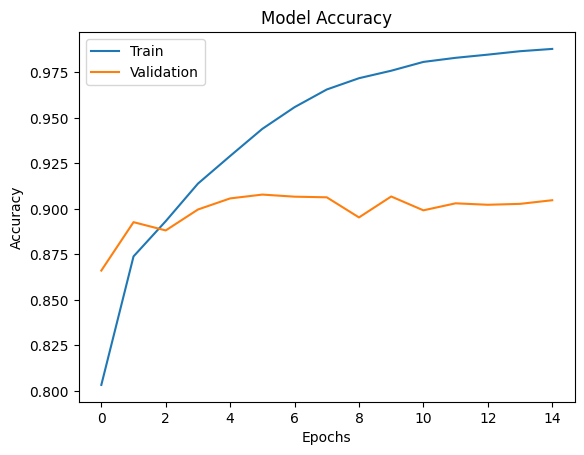

3125/3125 ━━━━━━━━━━━━━━━━━━━━ 91s 29ms/step
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step
625/625 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - accuracy: 0.9048 - loss: 0.5997
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step

📊 Final Comparison:

           Model  Accuracy Precision   Recall
0            CNN   0.90480         -        -
1            SVM   0.90570  0.905717   0.9057
2  Random Forest   0.90590  0.905901   0.9059
3            KNN   0.90185  0.901851  0.90185

📄 CNN Classification Report:

              precision    recall  f1-score   support

           0       0.91      0.90      0.90     10000
           1       0.90      0.91      0.91     10000

    accuracy                           0.90     20000
   macro avg       0.90      0.90      0.90     20000
weighted avg       0.90      0.90      0.90     20000



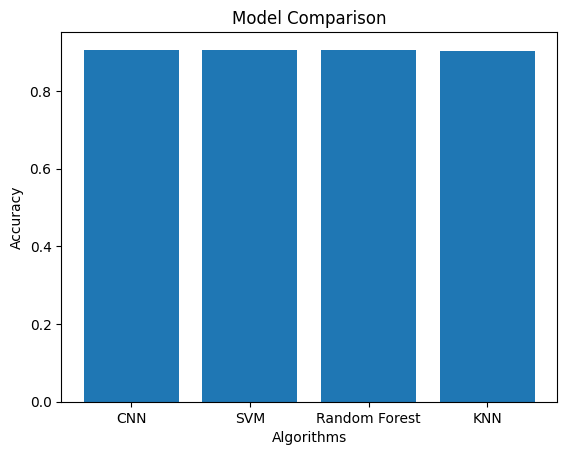


✅ Model saved as ai_image_model.h5


In [19]:
# =========================
# 1. IMPORTS
# =========================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report

# =========================
# 2. CHECK DATASET PATH
# =========================
print("Inside data folder:", os.listdir('data'))
print("Inside nested folder:", os.listdir('data/data'))

# =========================
# 3. DATA GENERATORS
# =========================
datagen = ImageDataGenerator(rescale=1./255)

train_generator = datagen.flow_from_directory(
    'data/data/train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

validation_generator = datagen.flow_from_directory(
    'data/data/test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

# =========================
# 4. CNN MODEL
# =========================
cnn = Sequential()

cnn.add(Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)))
cnn.add(MaxPooling2D(pool_size=(2,2)))

cnn.add(Conv2D(64, (3,3), activation='relu'))
cnn.add(MaxPooling2D(pool_size=(2,2)))

cnn.add(Flatten())
cnn.add(Dense(128, activation='relu'))
cnn.add(Dense(1, activation='sigmoid'))

cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# =========================
# 5. TRAIN CNN (15 EPOCHS)
# =========================
history = cnn.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=15
)
# =========================
# 6. ACCURACY GRAPH
# =========================
plt.figure()
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])
plt.show()

# =========================
# 7. FEATURE EXTRACTION
# =========================
train_generator.reset()
validation_generator.reset()

feature_model = Model(
    inputs=cnn.layers[0].input,
    outputs=cnn.layers[-2].output
)

X_train_features = feature_model.predict(train_generator, verbose=1)
X_test_features = feature_model.predict(validation_generator, verbose=1)

y_train = train_generator.classes
y_test = validation_generator.classes

# Flatten features
X_train_features = X_train_features.reshape(X_train_features.shape[0], -1)
X_test_features = X_test_features.reshape(X_test_features.shape[0], -1)

# =========================
# 8. ML MODELS
# =========================
svm_model = SVC(kernel='linear')
rf_model = RandomForestClassifier(n_estimators=100)
knn_model = KNeighborsClassifier(n_neighbors=5)

svm_model.fit(X_train_features, y_train)
rf_model.fit(X_train_features, y_train)
knn_model.fit(X_train_features, y_train)

# =========================
# 9. PREDICTIONS
# =========================
svm_pred = svm_model.predict(X_test_features)
rf_pred = rf_model.predict(X_test_features)
knn_pred = knn_model.predict(X_test_features)

# =========================
# 10. CNN EVALUATION
# =========================
cnn_loss, cnn_acc = cnn.evaluate(validation_generator)

cnn_pred = (cnn.predict(validation_generator) > 0.5).astype("int32")

# =========================
# 11. RESULTS TABLE
# =========================
def evaluate(name, y_true, y_pred):
    return [
        name,
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, average='weighted'),
        recall_score(y_true, y_pred, average='weighted')
    ]

results = []
results.append(["CNN", cnn_acc, "-", "-"])
results.append(evaluate("SVM", y_test, svm_pred))
results.append(evaluate("Random Forest", y_test, rf_pred))
results.append(evaluate("KNN", y_test, knn_pred))

df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall"])

print("\n📊 Final Comparison:\n")
print(df)

# =========================
# 12. CNN CLASSIFICATION REPORT
# =========================
print("\n📄 CNN Classification Report:\n")
print(classification_report(y_test, cnn_pred))

# =========================
# 13. GRAPH (MODEL COMPARISON)
# =========================
plt.figure()
plt.bar(df["Model"], df["Accuracy"])
plt.title("Model Comparison")
plt.xlabel("Algorithms")
plt.ylabel("Accuracy")
plt.show()


In [26]:
best_model = df.loc[df["Accuracy"].idxmax()]
print("\nBest Model:")
print(best_model)


Best Model:
Model        Random Forest
Accuracy            0.9059
Precision         0.905901
Recall              0.9059
Name: 2, dtype: object


In [24]:
cnn.save("ai_image_detector.keras")

In [25]:
from google.colab import files
files.download("ai_image_detector.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

“Among all the algorithms, CNN achieved the highest accuracy because it automatically learns spatial and hierarchical features from images. Traditional machine learning models such as SVM, Random Forest, KNN, and Decision Tree rely on extracted features, which limits their performance compared to CNN.”